**Simple Linear Regression Model**

In [2]:
# Importing all the necessary dependencies
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import sklearn.compose
from sklearn.compose import ColumnTransformer 

import sklearn.impute
from sklearn.impute import SimpleImputer

import sklearn.pipeline
from sklearn.pipeline import Pipeline

import sklearn.model_selection
from sklearn.model_selection import train_test_split

import sklearn.preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler

import sklearn.linear_model 
from sklearn.linear_model import LinearRegression

import sklearn.metrics
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
# Load Dataset
df = pd.read_csv("2) Stock Prices Data Set.csv")

In [4]:
df.head()

,symbol,date,open,high,low,close,volume
0,AAL,2014-01-02,25.0700,25.8200,25.0600,25.3600,8998943
1,AAPL,2014-01-02,79.3828,79.5756,78.8601,79.0185,58791957
2,AAP,2014-01-02,110.3600,111.8800,109.2900,109.7400,542711
3,ABBV,2014-01-02,52.1200,52.3300,51.5200,51.9800,4569061
4,ABC,2014-01-02,70.1100,70.2300,69.4800,69.8900,1148391


In [5]:
df.tail()

,symbol,date,open,high,low,close,volume
497467,XYL,2017-12-29,68.53,68.80,67.92,68.20,1046677
497468,YUM,2017-12-29,82.64,82.71,81.59,81.61,1347613
497469,ZBH,2017-12-29,121.75,121.95,120.62,120.67,1023624
497470,ZION,2017-12-29,51.28,51.55,50.81,50.83,1261916
497471,ZTS,2017-12-29,72.55,72.76,72.04,72.04,1704122


In [6]:
print(df.isnull().sum())

symbol     0
date       0
open      11
high       8
low        8
close      0
volume     0
dtype: int64


In [7]:
# Remove inconsistent data and assign values to the feature(s)[X] and target[y]

data = df[['open', 'close']].dropna()

data['open'] =pd.to_numeric(data['open'], errors="coerce")
data['close'] =pd.to_numeric(data['close'], errors="coerce")
data_df = data.dropna()


X = data_df[['open']]
y = data_df['close']

In [8]:
# Split your dataset into train-set and test-set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
# Running and Testing the Model
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['open']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.02668
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [18]:
y_pred = model.predict(X_test)

In [19]:
# Calculating Mean Squared Error and R-Squared values
mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

In [20]:
print("Model Evaluation:")
print(f'Slope (Coefficient): {model.coef_[0]:.4f}')
print(f'Intercept: {model.intercept_:.4f}')
print(f'Mean Squared Error(MSE): {mse:.4f}')
print(f'R-Squared: {r2:.4f}')

Model Evaluation:
Slope (Coefficient): 0.9999
Intercept: 0.0267
Mean Squared Error(MSE): 2.7261
R-Squared: 0.9997


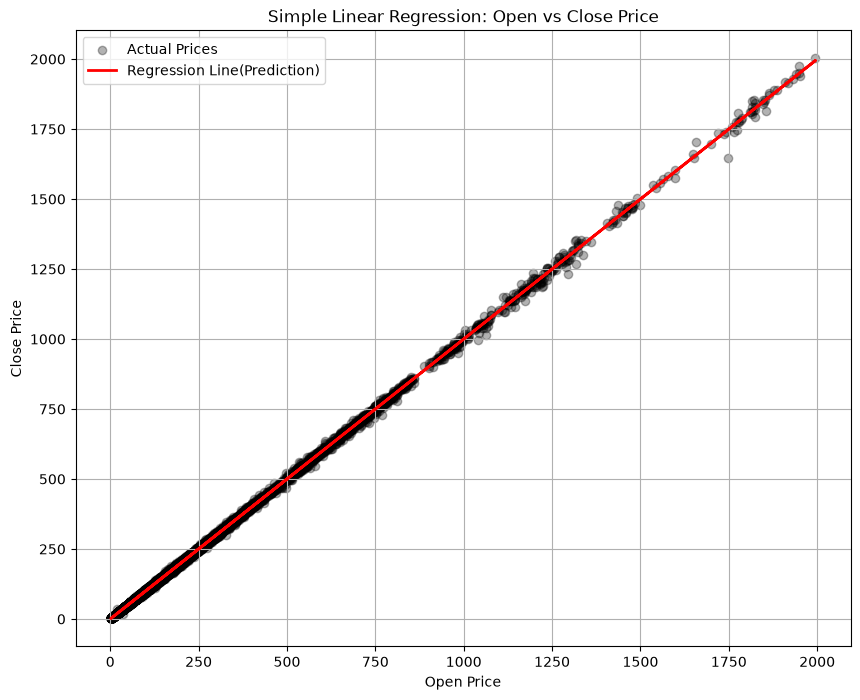

In [21]:
# Diagrammatic representation of the Linear Regression Model with the line of best fit
plt.figure(figsize=[10, 8])
plt.scatter(X_test, y_test, color='black', alpha=0.3, label='Actual Prices')
plt.plot(
    X_test,
    y_pred,
    color='red',
    linewidth=2,
    label='Regression Line(Prediction)',
)
plt.xlabel('Open Price')
plt.ylabel('Close Price')
plt.title('Simple Linear Regression: Open vs Close Price')
plt.legend()
plt.grid()
plt.show()